## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


1.1

The point estimate of the ATE is −0.01, calculated as the Invasive mean minus the Conservative mean. This indicates that the Invasive group has an observed survival rate about 1 percentage point lower than the Conservative group. Based on this point estimate, I would prefer not to receive the balloon pump because the Conservative group has the higher observed survival rate.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

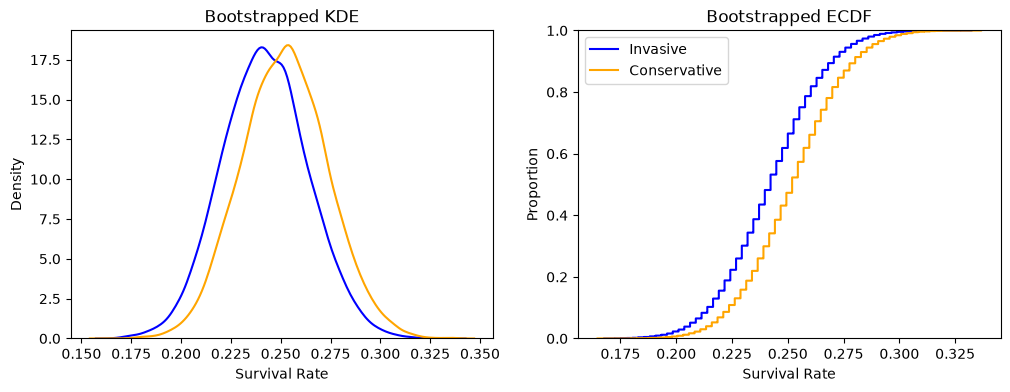

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Proportion')

plt.legend()
plt.show()

1.3

The two groups have similar bootstrap distributions, but the Invasive group has slightly lower estimated survival rates. The KDEs are bell-shaped, have similar spreads, and overlap substantially. The Invasive KDE is slightly to the left of the Conservative KDE. The ECDFs show the same relationship. The Invasive group reaches a given cumulative proportion at a slightly lower survival rate. The difference between the groups is small relative to the spread of their bootstrap estimates.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

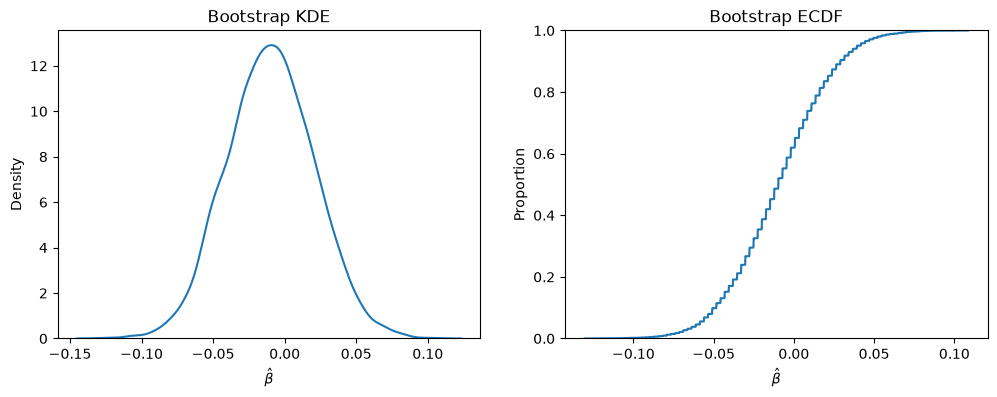

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


1.4

Yes, the ATE KDE is roughly bell-shaped, with its center slightly below zero. The plotted bootstrap estimates extend roughly from −0.12 to 0.10, representing survival-rate differences from about 12 percentage points lower to 10 percentage points higher for the Invasive group compared with the Conservative group. Therefore, the bootstrap results include effects favoring either treatment.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05856942  0.03930942]
95% CI: [-0.06884574  0.04957199]
99% CI: [-0.08933861  0.07015746]


1.5

Yes, zero is included in all 3 confidence intervals. Therefore, I fail to reject the null hypothesis that the effect size is zero at significance levels 0.10, 0.05, and 0.01. Additionally, I do not reject the null hypothesis at any of these levels.

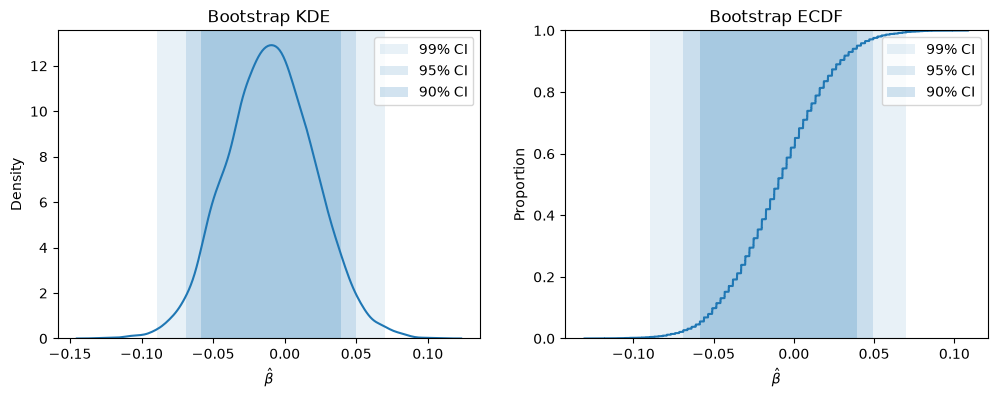

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

1.6

I compared the survival rates of the Invasive and Conservative groups and found an estimated ATE of −0.01. Under the lab’s survival coding, this means the observed survival rate was about 1 percentage point lower in the Invasive group. Based on that estimate alone, the Conservative treatment appears preferable. To assess how much uncertainty there was in this difference, I resampled each group separately 10,000 times and calculated their average outcomes and the ATE for each repetition. The group KDEs overlapped substantially, and the ATE distribution was roughly bell-shaped with its center slightly below zero. The 90%, 95%, and 99% confidence intervals all included zero, so I failed to reject the null hypothesis of a zero treatment effect at each corresponding significance level. I therefore found no statistically significant evidence that the balloon pump improves survival compared with the Conservative treatment. However, the intervals included effects in both directions, so I also cannot conclude that the balloon pump reduces survival or has no effect. What I learned at the end of the day is that the small observed difference favoring the Conservative treatment is not enough to establish which treatment has the higher true survival rate.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [8]:
df_Part_2 = pd.read_csv('./data/diabetes.csv')
df_Part_2['success'] = (df_Part_2['outcome'] == 'success').astype(int)

print(pd.crosstab(df_Part_2['treatment'], df_Part_2['outcome']), '\n')

mean_met = df_Part_2.loc[df_Part_2['treatment'] == 'met', 'success'].mean()
mean_rosi = df_Part_2.loc[df_Part_2['treatment'] == 'rosi', 'success'].mean()
mean_lifestyle = df_Part_2.loc[df_Part_2['treatment'] == 'lifestyle', 'success'].mean()

print('Average outcome for metformin:', np.round(mean_met, 6))
print('Average outcome for rosiglitazone:', np.round(mean_rosi, 6))
print('Average outcome for lifestyle:', np.round(mean_lifestyle, 6))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Average outcome for metformin: 0.482759
Average outcome for rosiglitazone: 0.613734
Average outcome for lifestyle: 0.534188


2.1

The average outcomes are 0.482759 for metformin (met), 0.613734 for rosiglitazone (rosi), and 0.534188 for lifestyle.

In [9]:
R_Part_2 = 10_000
rng = np.random.default_rng(100)

df_met = df_Part_2.loc[df_Part_2['treatment'] == 'met', :]
df_rosi = df_Part_2.loc[df_Part_2['treatment'] == 'rosi', :]
df_lifestyle = df_Part_2.loc[df_Part_2['treatment'] == 'lifestyle', :]

outcome_met = []
outcome_rosi = []
outcome_lifestyle = []

for t in range(R_Part_2):
    df_mt = df_met.sample(frac=1.0, replace=True, random_state=rng)
    df_rt = df_rosi.sample(frac=1.0, replace=True, random_state=rng)
    df_lt = df_lifestyle.sample(frac=1.0, replace=True, random_state=rng)

    omt = df_mt['success'].mean()
    ort = df_rt['success'].mean()
    olt = df_lt['success'].mean()

    outcome_met.append(omt)
    outcome_rosi.append(ort)
    outcome_lifestyle.append(olt)

outcome_met = np.array(outcome_met)
outcome_rosi = np.array(outcome_rosi)
outcome_lifestyle = np.array(outcome_lifestyle)

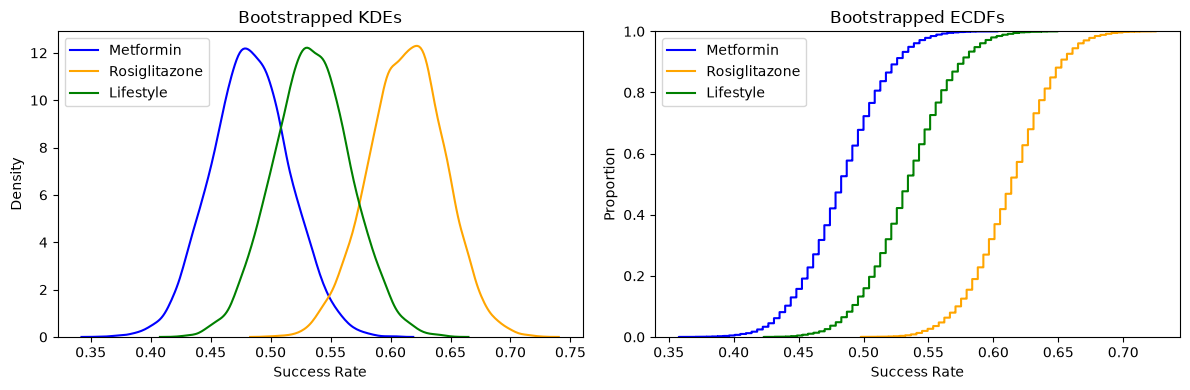

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# My Bootstrap KDEs
sns.kdeplot(outcome_met, label='Metformin', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[0])
sns.kdeplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[0])

ax[0].set(title='Bootstrapped KDEs', xlabel='Success Rate', ylabel='Density')
ax[0].legend()

# My Bootstrap ECDFs
sns.ecdfplot(outcome_met, label='Metformin', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[1])
sns.ecdfplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[1])

ax[1].set(title='Bootstrapped ECDFs', xlabel='Success Rate', ylabel='Proportion')
ax[1].legend()

plt.tight_layout()
fig_outcomes = fig
plt.show()

2.3

The bootstrap distributions show the highest success rates for rosiglitazone, the lowest for metformin, and intermediate rates for lifestyle. In the KDE plot, the rosiglitazone curve is farthest to the right, the metformin curve is farthest to the left, and the lifestyle curve is between them. All three curves are roughly bell-shaped and have similar spreads. The curves overlap, particularly for metformin and lifestyle. The ECDF plot shows the same relationship. At a given cumulative proportion, rosiglitazone has the highest success rate, lifestyle has an intermediate success rate, and metformin has the lowest. The plots suggest differences between the groups, but the pairwise confidence intervals are needed to assess whether those differences are statistically significant.

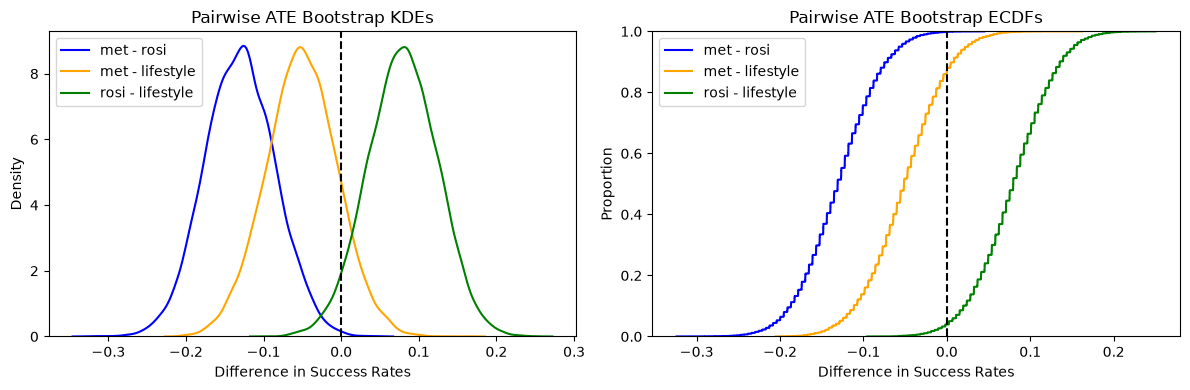

In [11]:
ate_met_rosi = outcome_met - outcome_rosi
ate_met_lifestyle = outcome_met - outcome_lifestyle
ate_rosi_lifestyle = outcome_rosi - outcome_lifestyle

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# MY Pairwise ATE KDEs
sns.kdeplot(ate_met_rosi, label='met - rosi', color='blue', ax=ax[0])
sns.kdeplot(ate_met_lifestyle, label='met - lifestyle', color='orange', ax=ax[0])
sns.kdeplot(ate_rosi_lifestyle, label='rosi - lifestyle', color='green', ax=ax[0])

ax[0].axvline(0, color='black', linestyle='--')
ax[0].set_xlabel('Difference in Success Rates')
ax[0].set_ylabel('Density')
ax[0].set_title('Pairwise ATE Bootstrap KDEs')
ax[0].legend()

# My Pairwise ATE ECDFs
sns.ecdfplot(ate_met_rosi, label='met - rosi', color='blue', ax=ax[1])
sns.ecdfplot(ate_met_lifestyle, label='met - lifestyle', color='orange', ax=ax[1])
sns.ecdfplot(ate_rosi_lifestyle, label='rosi - lifestyle', color='green', ax=ax[1])

ax[1].axvline(0, color='black', linestyle='--')
ax[1].set_xlabel('Difference in Success Rates')
ax[1].set_ylabel('Proportion')
ax[1].set_title('Pairwise ATE Bootstrap ECDFs')
ax[1].legend()

plt.tight_layout()
fig_ate = fig
plt.show()

In [12]:
comparisons = {
    'met - rosi': ate_met_rosi,
    'met - lifestyle': ate_met_lifestyle,
    'rosi - lifestyle': ate_rosi_lifestyle}

rows = []

for comparison, values in comparisons.items():
    ci90 = np.quantile(values, [.05, .95])
    ci95 = np.quantile(values, [.025, .975])
    ci99 = np.quantile(values, [.005, .995])

    rows.append([comparison, ci90[0], ci90[1], ci95[0], ci95[1], ci99[0], ci99[1]])

ci_table = pd.DataFrame(
    rows,
    columns = ['Comparison', '90% lower', '90% upper', '95% lower', '95% upper', '99% lower', '99% upper'])

display(ci_table)

,Comparison,90% lower,90% upper,95% lower,95% upper,99% lower,99% upper
0,met - rosi,-0.204048,-0.053667,-0.217016,-0.040717,-0.247096,-0.014836
1,met - lifestyle,-0.128463,0.025532,-0.141579,0.038646,-0.167293,0.064582
2,rosi - lifestyle,0.002659,0.152361,-0.010326,0.165236,-0.036206,0.195096


2.5

I found a statistically significant difference favoring rosiglitazone over metformin at significance levels 0.10, 0.05, and 0.01. For metformin minus rosiglitazone, the 90% confidence interval is [−0.204048, −0.053667], the 95% interval is [−0.217016, −0.040717], and the 99% interval is [−0.247096, −0.014836]. All three intervals are entirely below zero, so I reject the null hypothesis of a zero treatment effect at each level. The negative differences indicate a higher success rate for rosiglitazone.

I did not find a statistically significant difference between metformin and lifestyle at any of these levels. The 90% confidence interval is [−0.128463, 0.025532], the 95% interval is [−0.141579, 0.038646], and the 99% interval is [−0.167293, 0.064582]. All three include zero, so I fail to reject the null hypothesis for this comparison.

I did find a statistically significant difference favoring rosiglitazone over lifestyle at significance level 0.10, but not at 0.05 or 0.01. The 90% confidence interval for rosiglitazone minus lifestyle is [0.002659, 0.152361], which excludes zero. However, the 95% interval [−0.010326, 0.165236] and the 99% interval [−0.036206, 0.195096] both include zero. 

Rosiglitazone seems most effective because it has the highest observed success rate, 0.613734. At significance level 0.05, the evidence supports its advantage over metformin but does not establish an advantage over lifestyle.

Table 1. Observed outcomes by treatment
outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Average outcome for metformin: 0.482759
Average outcome for rosiglitazone: 0.613734
Average outcome for lifestyle: 0.534188
--------------------------------------------------------------
Table 2. Percentile bootstrap confidence intervals


,Comparison,90% lower,90% upper,95% lower,95% upper,99% lower,99% upper
0,met - rosi,-0.204048,-0.053667,-0.217016,-0.040717,-0.247096,-0.014836
1,met - lifestyle,-0.128463,0.025532,-0.141579,0.038646,-0.167293,0.064582
2,rosi - lifestyle,0.002659,0.152361,-0.010326,0.165236,-0.036206,0.195096


Figure 1. Bootstrap distributions of treatment success rates


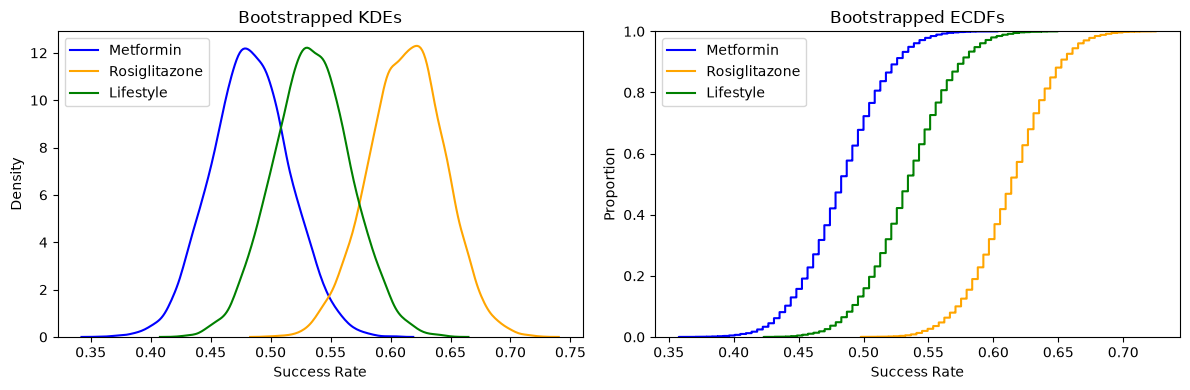

Figure 2. Bootstrap distributions of pairwise treatment effects


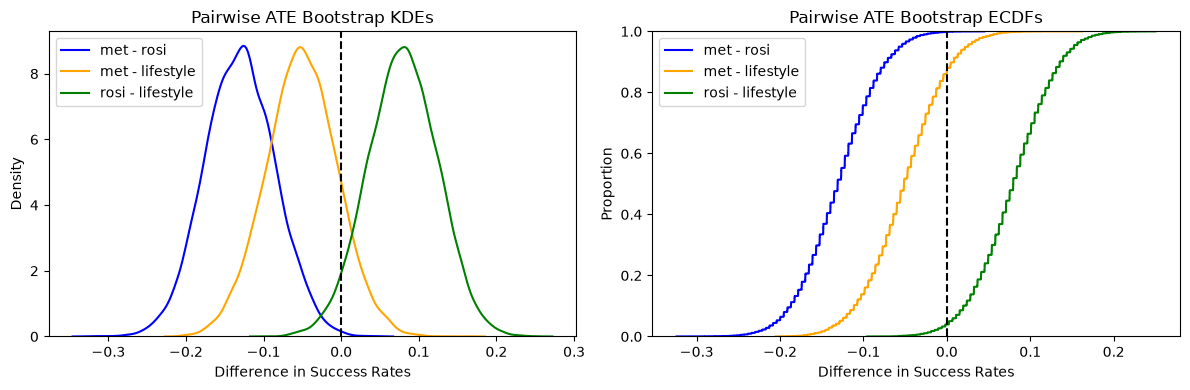

In [13]:
# My Summary Code

print('Table 1. Observed outcomes by treatment')

df_Part_2 = pd.read_csv('./data/diabetes.csv')
df_Part_2['success'] = (df_Part_2['outcome'] == 'success').astype(int)

print(pd.crosstab(df_Part_2['treatment'], df_Part_2['outcome']), '\n')

mean_met = df_Part_2.loc[df_Part_2['treatment'] == 'met', 'success'].mean()
mean_rosi = df_Part_2.loc[df_Part_2['treatment'] == 'rosi', 'success'].mean()
mean_lifestyle = df_Part_2.loc[df_Part_2['treatment'] == 'lifestyle', 'success'].mean()

print('Average outcome for metformin:', np.round(mean_met, 6))
print('Average outcome for rosiglitazone:', np.round(mean_rosi, 6))
print('Average outcome for lifestyle:', np.round(mean_lifestyle, 6))

print('--------------------------------------------------------------')

print('Table 2. Percentile bootstrap confidence intervals')
display(ci_table)

print('Figure 1. Bootstrap distributions of treatment success rates')
display(fig_outcomes)

print('Figure 2. Bootstrap distributions of pairwise treatment effects')
display(fig_ate)

2.6

I analyzed the outcomes of 699 participants in a randomized controlled trial comparing metformin, rosiglitazone, and lifestyle adjustments to reduce progression from prediabetes to diabetes. As shown in Table 1, the metformin group had 112 successes and 120 failures, the rosiglitazone group had 143 successes and 90 failures, and the lifestyle group had 125 successes and 109 failures. I coded successful outcomes as 1 and failures as 0, so the average outcome for each group represents its success rate. These averages were 0.482759 for metformin, 0.613734 for rosiglitazone, and 0.534188 for lifestyle. Rosiglitazone had the highest observed success rate, followed by lifestyle and metformin. These observed differences provide the starting point for assessing whether the interventions differ in effectiveness.

To assess uncertainty, I resampled participants with replacement separately within each treatment group 10,000 times, preserving the original group sizes. For each repetition, I calculated the three average outcomes and their pairwise differences. Figure 1 shows the KDEs and ECDFs of the bootstrapped success rates. The KDEs are roughly bell-shaped with similar spreads, and their centers follow the same ordering as the observed success rates. Figure 2 shows the bootstrap distributions of the pairwise ATEs. Each comparison subtracts the second treatment's success rate from the first, so negative values favor the second treatment and positive values favor the first.

The percentile bootstrap confidence intervals in Table 2 provide statistically significant evidence favoring rosiglitazone over metformin at significance levels 0.10, 0.05, and 0.01. All three intervals for metformin minus rosiglitazone are below zero, including the 95% interval [−0.217016, −0.040717]. For metformin minus lifestyle, all three intervals include zero; the 95% interval is [−0.141579, 0.038646]. For rosiglitazone minus lifestyle, the 90% interval [0.002659, 0.152361] excludes zero, but the 95% interval [−0.010326, 0.165236] and the 99% interval include zero. The evidence favoring rosiglitazone over lifestyle is therefore significant at level 0.10, but not at 0.05 or 0.01.

Based on the recorded success outcome, I found evidence supporting the selection of rosiglitazone over metformin. Metformin had the lowest observed success rate, and the comparisons provide no evidence of an advantage over either alternative. Lifestyle had a higher observed success rate than metformin, but that difference was not statistically significant. The analysis also did not establish that lifestyle was less effective than rosiglitazone at significance level 0.05. I therefore find support for preferring rosiglitazone to metformin, but insufficient evidence at that level to choose between rosiglitazone and lifestyle. These findings compare the three interventions with one another; without an untreated group, they do not establish each intervention's effectiveness relative to no intervention.